In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

path = "C:\\Users\\nikit\\Nikita-Osaula---Struktury-Danych\\raster\\tucholski_fragment.tif"

with rasterio.open(path) as src:
    raster = src.read()
print(raster) # Co jest wynikiem print?
print(raster.shape) # Jak interpretować te dane?  


[[[ 31  32  32 ...  23  22  20]
  [ 32  33  32 ...  22  22  23]
  [ 34  33  31 ...  19  20  28]
  ...
  [ 70  70  74 ...  49  85  87]
  [ 77  75  76 ...  21  41  49]
  [ 73  73  75 ...  20  23  39]]

 [[ 53  57  57 ...  28  28  29]
  [ 55  60  58 ...  29  29  29]
  [ 58  59  56 ...  29  27  32]
  ...
  [ 52  53  53 ...  39  67  72]
  [ 57  57  56 ...  23  39  56]
  [ 56  55  56 ...  30  29  46]]

 [[ 23  24  22 ...  18  16  17]
  [ 22  25  25 ...  18  15  16]
  [ 22  24  23 ...  15  14  15]
  ...
  [ 32  32  33 ...  23  41  47]
  [ 34  35  36 ...  15  22  28]
  [ 36  33  33 ...  14  12  22]]

 [[255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  ...
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]]]
(4, 794, 1034)


(794, 1034, 3)


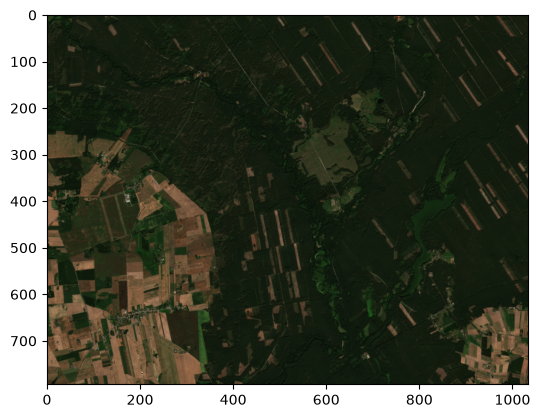

In [ ]:

rgb = np.moveaxis(raster[0:3], 0, -1)
print(rgb.shape)
plt.imshow(rgb)
plt.show()   


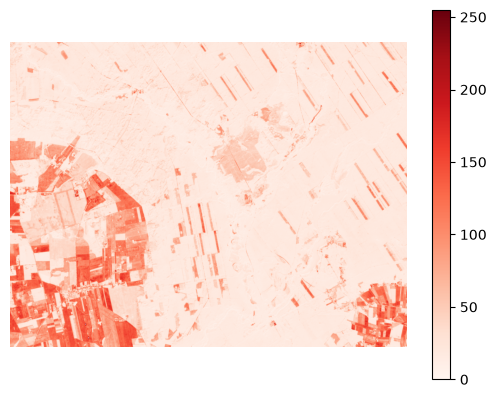

In [10]:
plt.imshow(raster[0], cmap="Reds")
plt.colorbar()
plt.axis("off")
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [709..18832].


[[[1221 1237 1256 ... 1238 1229 1204]
  [1228 1258 1286 ... 1238 1210 1199]
  [1261 1282 1278 ... 1235 1211 1220]
  ...
  [1249 1252 1248 ... 1375 1382 1361]
  [1253 1249 1247 ... 1379 1366 1362]
  [1235 1245 1251 ... 1370 1341 1354]]

 [[1368 1339 1376 ... 1457 1431 1417]
  [1352 1360 1402 ... 1453 1416 1411]
  [1381 1414 1391 ... 1437 1406 1416]
  ...
  [1359 1348 1343 ... 1547 1536 1526]
  [1357 1353 1348 ... 1544 1552 1540]
  [1348 1357 1359 ... 1544 1538 1542]]

 [[1337 1299 1324 ... 1326 1312 1334]
  [1333 1349 1369 ... 1317 1307 1334]
  [1334 1345 1358 ... 1319 1321 1330]
  ...
  [1241 1220 1221 ... 1259 1254 1260]
  [1222 1206 1225 ... 1253 1261 1253]
  [1232 1233 1229 ... 1254 1242 1250]]]


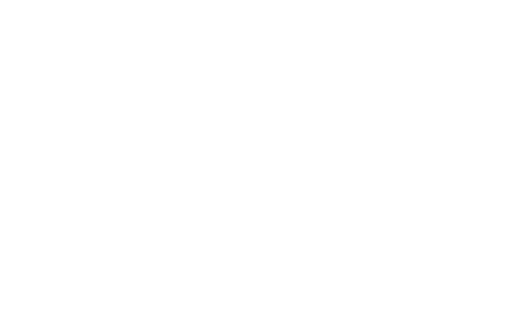

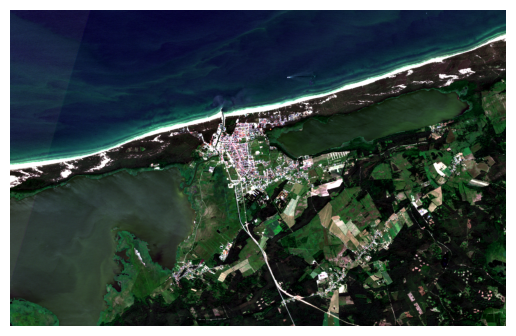

In [21]:
path2 = "C:\\Users\\nikit\\Nikita-Osaula---Struktury-Danych\\raster\\wybrzeze\\sentinel-2-l2a_2026-06-26_S2C_MSIL2A_20260626T101021_R022_T33UXA_20260626T152309\\sentinel-2-l2a_2026-06-26_S2C_MSIL2A_20260626T101021_R022_T33UXA_20260626T152309_"

with rasterio.open(path2 + "B04.tif") as src:
    red = src.read(1)

with rasterio.open(path2 + "B03.tif") as src:
    green = src.read(1)

with rasterio.open(path2 + "B02.tif") as src:
    blue = src.read(1)


rgb_stacked = np.stack([red, green, blue])
print(rgb_stacked) # Połączone kanały z 3 plików

raster_rgb = np.moveaxis(rgb_stacked, 0, -1)

plt.imshow(raster_rgb)
plt.axis("off")
plt.show()

raster_rgb2 = raster_rgb.astype(float).copy()
for i in range(3):
    low = np.percentile(raster_rgb2[:, :, i], 2)
    high = np.percentile(raster_rgb2[:, :, i], 98)

    raster_rgb2[:, :, i] = np.clip(
        (raster_rgb2[:, :, i] - low) / (high - low),
        0,
        1
    )

plt.imshow(raster_rgb2) # Wartości 0.0 - 1.0
plt.axis("off")
plt.show()

In [22]:

print(raster_rgb2.shape) # To już robiliśmy wyżej

print(raster_rgb2.dtype)
print(raster_rgb2.min()) 
print(raster_rgb2.max())

(1019, 1599, 3)
float64
0.0
1.0


In [ ]:
# Średnia wartość:
print(raster_rgb2.mean()) 
print(raster_rgb2[:, :, 0].mean())
print(raster_rgb2[:, :, 1].mean())
print(raster_rgb2[:, :, 2].mean())
# Czym się różnią powyższe średnie? 

0.187517640655457
0.15217028067086555
0.20938614566354183
0.20099649563196376


In [ ]:
# Analogicznie można badać np. medianę czy odchylenie standardowe:
print(np.median(raster_rgb2))
print(np.std(raster_rgb2))
# Jak różniłyby się rozkłady per poszczególny kanał?  

0.14546965918536992
0.18693536102663882


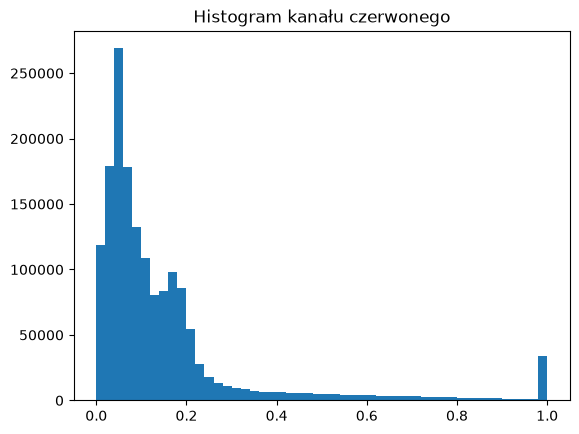

In [ ]:
# Przykładowy histogram:
plt.hist(raster_rgb2[:, :, 0].flatten(), bins=50)
plt.title("Histogram kanału czerwonego")
plt.show() 

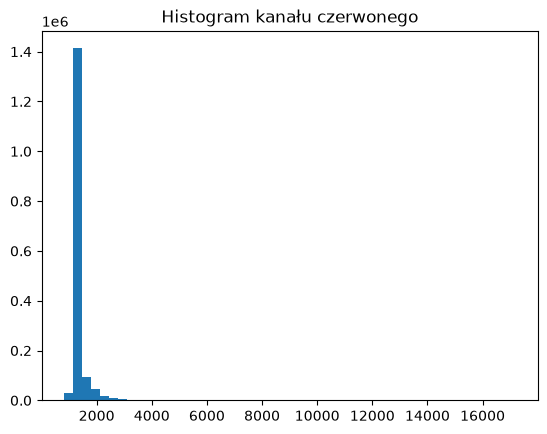

In [26]:
# Przykładowy histogram przed normalizacją:
plt.hist(raster_rgb[:, :, 0].flatten(), bins=50)
plt.title("Histogram kanału czerwonego")
plt.show()
# Dlaczego normalizacja aż tak zmienia wyniki histogramu? Jak wyglądałoby to dla innych kanałów?

In [ ]:
# Wysokość czy szerokość rastra wyciągnąć możemy ze znanego już nam raster_rgb2.shape
# Niektóre informacje można jednak pobrać tylko bezpośrednio z pliku, a nie z numpy array. Dlaczego?
with rasterio.open(path2 + "B04.tif") as src:
    print(src.nodata)
    print(src.crs)
    print(src.bounds)
    print(src.res)
    print(src.transform)
    # Jak rozumieć powyższe wartości?

    # Wykorzystując dostęp do plików możemy też przepytywać dane pod względem współrzędnych:
    print(src.xy(100, 100))
    print(src.index(658000, 6074300)) 

None
PROJCS["WGS 84 / UTM zone 33N",GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",15],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
BoundingBox(left=657240.0, bottom=6065160.0, right=673230.0, top=6075350.0)
(10.0, 10.0)
| 10.00, 0.00, 657240.00|
| 0.00,-10.00, 6075350.00|
| 0.00, 0.00, 1.00|
(np.float64(658245.0), np.float64(6074345.0))
(105, 76)


In [28]:
rgb_to_save = np.moveaxis(raster_rgb2, -1, 0)


# Wersja zapisu #1:
with rasterio.open(
    "rgb_output1.tif",
    "w",
    driver="GTiff",
    height=rgb_to_save.shape[1],
    width=rgb_to_save.shape[2],
    count=3,
    dtype=rgb_to_save.dtype
) as dst:
    dst.write(rgb_to_save)



c:\Users\nikit\AppData\Local\Programs\Python\Python312\Lib\site-packages\rasterio\__init__.py:389: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(


In [ ]:
# Wersja zapisu #2:
with rasterio.open(path2 + "B04.tif") as src:
    profile = src.profile
    print(profile)

    profile.update(
        count=3,
        dtype=rgb_to_save.dtype
    )

with rasterio.open(
    "rgb_output2.tif",
    "w",
    **profile # Rozpakowanie słownika
) as dst:
    dst.write(rgb_to_save)

# Czym różnią się obie wersje? Czy wynikowy plik będzie identyczny? 

{'driver': 'GTiff', 'dtype': 'uint16', 'nodata': None, 'width': 1599, 'height': 1019, 'count': 1, 'crs': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 33N",GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",15],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]'), 'transform': Affine(10.0, 0.0, 657240.0,
       0.0, -10.0, 6075350.0), 'blockxsize': 1599, 'blockysize': 2, 'tiled': False, 'interleave': 'band'}


[[[1163 1150 1193 ... 1671 1466 1432]
  [1204 1180 1146 ... 1710 1380 1385]
  [1146 1155 1160 ... 1734 1460 1626]
  ...
  [1186 1212 1219 ... 1668 1640 1619]
  [1218 1230 1222 ... 1689 1644 1667]
  [1229 1206 1198 ... 1618 1513 1611]]

 [[1339 1316 1370 ... 1766 1607 1514]
  [1431 1419 1331 ... 1778 1602 1614]
  [1319 1393 1426 ... 1756 1627 1685]
  ...
  [1274 1341 1367 ... 1611 1624 1612]
  [1340 1366 1354 ... 1555 1632 1623]
  [1329 1342 1325 ... 1590 1630 1542]]

 [[1183 1151 1155 ... 1488 1394 1297]
  [1194 1180 1151 ... 1473 1298 1300]
  [1148 1157 1171 ... 1496 1327 1481]
  ...
  [1173 1226 1224 ... 1382 1396 1367]
  [1208 1187 1195 ... 1346 1365 1367]
  [1189 1202 1193 ... 1339 1370 1363]]]


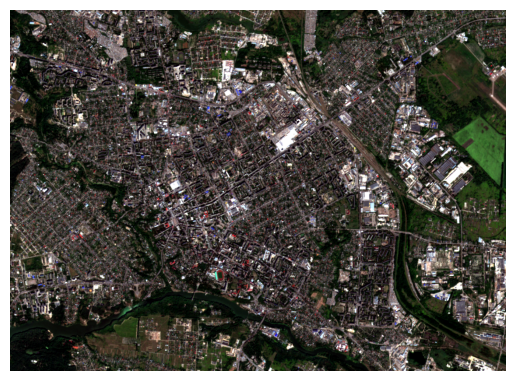

In [ ]:
rgb_path = "D:\\STRUKTURY DANYCH PRZESTRZENNYCH\\ua_rgb\\sentinel-2-l2a_2026-08-29_S2A_MSIL2A_20260829T091041_R050_T35UPR_20260829T140911_"

with rasterio.open(rgb_path + "B04.tif") as src:
    red = src.read(1)

with rasterio.open(rgb_path + "B03.tif") as src:
    green = src.read(1)

with rasterio.open(rgb_path + "B02.tif") as src:
    blue = src.read(1)

rgb_stacked = np.stack([red, green, blue])
print(rgb_stacked) 

raster_rgb_ua = np.moveaxis(rgb_stacked, 0, -1)

raster_ua = raster_rgb_ua.astype(float).copy()
for i in range(3):
    low = np.percentile(raster_ua[:,:,i], 2)
    high = np.percentile(raster_ua[:,:,i],99)

    raster_ua[:, :, i] = np.clip(
        (raster_ua[:, :, i] - low) / (high - low),
        0,
        1
    )

plt.imshow(raster_ua)
plt.axis("off")
plt.show() 


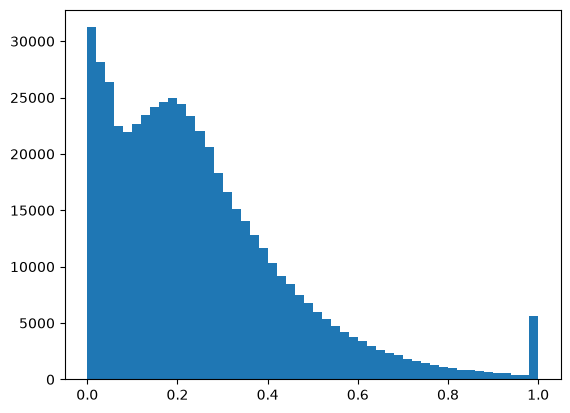

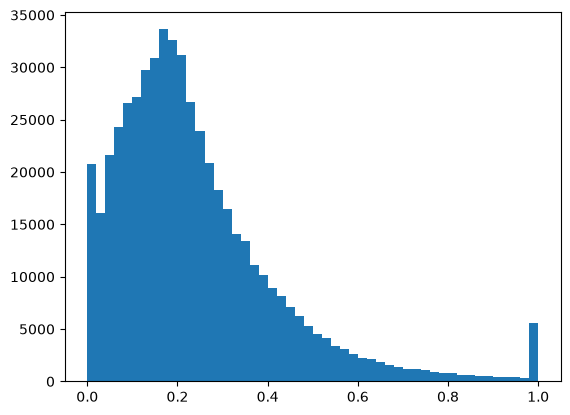

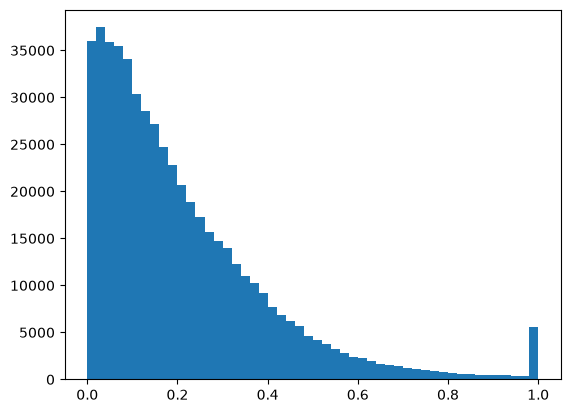

In [ ]:
 
for y in range(3):
    plt.hist(raster_ua[:, :,y].flatten(), bins=50)
    plt.show() 

In [106]:
rgb_path = "D:\\STRUKTURY DANYCH PRZESTRZENNYCH\\ua_rgb\\sentinel-2-l2a_2026-08-29_S2A_MSIL2A_20260829T091041_R050_T35UPR_20260829T140911_"

with rasterio.open(rgb_path + "B04.tif") as src:
    red = src.read(1)
    blocks = []

    for i in range(0 , 9, 3):
        for j in range(0, 9, 3):
            block = red[i:i+3, j:j+3]
            print(f"{i}-{i+2},  {j}-{j+2}:")
            print(block)
    
    center_x, center_y = src.xy(i + 3, j + 3)
    print(f" X={center_x}, Y={center_y}\n")
#with rasterio.open(rgb_path + "B03.tif") as src:
#    green = src.read(1)

#with rasterio.open(rgb_path + "B02.tif") as src:
#    blue = src.read(1)

0-2,  0-2:
[[1163 1150 1193]
 [1204 1180 1146]
 [1146 1155 1160]]
0-2,  3-5:
[[1291 1248 1177]
 [1294 1257 1175]
 [1203 1131 1149]]
0-2,  6-8:
[[1226 1268 1539]
 [1269 1256 1483]
 [1210 1254 1336]]
3-5,  0-2:
[[1134 1136 1152]
 [1199 1150 1146]
 [1187 1157 1168]]
3-5,  3-5:
[[1145 1138 1195]
 [1146 1170 1211]
 [1178 1162 1147]]
3-5,  6-8:
[[1172 1222 1258]
 [1188 1202 1159]
 [1157 1187 1169]]
6-8,  0-2:
[[1183 1203 1231]
 [1238 1245 1218]
 [1181 1217 1235]]
6-8,  3-5:
[[1208 1183 1134]
 [1241 1247 1177]
 [1266 1236 1175]]
6-8,  6-8:
[[1171 1190 1201]
 [1182 1183 1190]
 [1176 1179 1185]]
 X=615505.0, Y=5571795.0

